# **Data 400 Mini Project**

American Cinema in a Global Context

**Research question:** How do Letterboxd average ratings of American films compare with those of films made outside the United States, and does the difference vary by genre?
 **Unit of observation:** one film with an average rating and a listed country.


**Targets:** (1) average rating (regression), (2) rating tier Low / Medium / High (classification).

**Metrics:** RMSE and R² for regression; accuracy and macro-F1 for classification; each compared with a baseline.

**Origin rule:** only "USA" listed = *US only*; "USA" plus other countries = *US co-production*; no "USA" = *non-US*.

**Extension:** does adding cast information change the US effect?

**Test set:** used once per task, never for choosing models, cutoffs, or features.

In [1]:
!pip install kagglehub -q
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, re, kagglehub
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from sklearn.model_selection import train_test_split, cross_validate, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import Ridge, LassoCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
## 1. Get the data
!rm -rf /root/.cache/kagglehub/datasets/gsimonx37/letterboxd

ds = "gsimonx37/letterboxd"
def load(fname):
    return pd.read_csv(kagglehub.dataset_download(ds, path=fname, force_download=True))

movies    = load("movies.csv")
countries = load("countries.csv")
genres    = load("genres.csv")
themes    = load("themes.csv")
actors    = load("actors.csv")

100%|██████████| 106M/106M [00:01<00:00, 76.9MB/s]

Extracting zip of movies.csv...


100%|██████████| 2.39M/2.39M [00:00<00:00, 146MB/s]

Extracting zip of countries.csv...


100%|██████████| 3.04M/3.04M [00:00<00:00, 144MB/s]

Extracting zip of genres.csv...


100%|██████████| 502k/502k [00:00<00:00, 43.8MB/s]

Extracting zip of themes.csv...


100%|██████████| 76.3M/76.3M [00:00<00:00, 106MB/s]

Extracting zip of actors.csv...


In [3]:
for name, d in [("movies", movies), ("countries", countries), ("genres", genres), ("themes", themes), ("actors", actors)]:
    print("=====", name, d.shape)
    print(d.columns.tolist())
    display(d.head())

# %%
movies.info()
print(movies.isna().mean().sort_values(ascending=False))
print(movies["rating"].describe())

# %%
print(countries["country"].value_counts().head(20))
print(movies["date"].describe())

===== movies (941597, 7)
['id', 'name', 'date', 'tagline', 'description', 'minute', 'rating']


,id,name,date,tagline,description,minute,rating
0,1000001,Barbie,2023.0,She's everything. He's just Ken.,Barbie and Ken are having the time of their li...,114.0,3.86
1,1000002,Parasite,2019.0,Act like you own the place.,"All unemployed, Ki-taek's family takes peculia...",133.0,4.56
2,1000003,Everything Everywhere All at Once,2022.0,The universe is so much bigger than you realize.,An aging Chinese immigrant is swept up in an i...,140.0,4.30
3,1000004,Fight Club,1999.0,Mischief. Mayhem. Soap.,A ticking-time-bomb insomniac and a slippery s...,139.0,4.27
4,1000005,La La Land,2016.0,Here's to the fools who dream.,"Mia, an aspiring actress, serves lattes to mov...",129.0,4.09


===== countries (693476, 2)
['id', 'country']


,id,country
0,1000001,UK
1,1000001,USA
2,1000002,South Korea
3,1000003,USA
4,1000004,Germany


===== genres (1046849, 2)
['id', 'genre']


...

===== themes (125641, 2)
['id', 'theme']


,id,theme
0,1000001,Humanity and the world around us
1,1000001,Crude humor and satire
2,1000001,Moving relationship stories
3,1000001,Emotional and captivating fantasy storytelling
4,1000001,Surreal and thought-provoking visions of life ...


===== actors (5798450, 3)
['id', 'name', 'role']


,id,name,role
0,1000001,Margot Robbie,Barbie
1,1000001,Ryan Gosling,Ken
2,1000001,America Ferrera,Gloria
3,1000001,Ariana Greenblatt,Sasha
4,1000001,Issa Rae,Barbie


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 941597 entries, 0 to 941596
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   id           941597 non-null  int64  
 1   name         941587 non-null  object 
 2   date         849684 non-null  float64
 3   tagline      139387 non-null  object 
 4   description  780785 non-null  object 
 5   minute       760027 non-null  float64
 6   rating       90999 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 50.3+ MB
rating         0.903357
tagline        0.851967
minute         0.192832
description    0.170786
date           0.097614
name           0.000011
id             0.000000
dtype: float64
count    90999.000000
mean         3.244043
std          0.417281
min          0.880000
25%          3.020000
50%          3.300000
75%          3.510000
max          4.690000
Name: rating, dtype: float64
country
USA                   174489
France         

In [4]:
## 2. Build one row per film

# Keep rated films with a plausible year
df = movies.dropna(subset=["rating", "date"]).copy()
df = df[(df["date"] >= 1900) & (df["date"] <= 2025)]
df["year"] = df["date"].astype(int)
df["decade"] = (df["year"] // 10 * 10).astype(str)

# Origin rule: US only / US co-production / non-US
c = (countries.assign(is_us=countries["country"].eq("USA"))
              .groupby("id").agg(n=("country", "nunique"), has_us=("is_us", "any")))
c["origin"] = np.where(~c["has_us"], "non-US",
                np.where(c["n"] == 1, "US only", "US co-production"))
df = df.merge(c["origin"], left_on="id", right_index=True, how="inner")  # drops films with no country

# Genres: small fixed vocabulary, keep all (multi-hot)
g = pd.crosstab(genres["id"], genres["genre"]).clip(upper=1).add_prefix("g_")
df = df.merge(g, left_on="id", right_index=True, how="left")
g_cols = g.columns.tolist()
df[g_cols] = df[g_cols].fillna(0)

print(df.shape)
print(df["origin"].value_counts())
print(df["decade"].value_counts().sort_index())

(87286, 29)
origin
non-US              46979
US only             30856
US co-production     9451
Name: count, dtype: int64
decade
1900      392
1910      386
1920      685
1930     1915
1940     2098
1950     2765
1960     3974
1970     5257
1980     6280
1990     7376
2000    13038
2010    27700
2020    15420
Name: count, dtype: int64


In [5]:
## 3. Split BEFORE exploring (stratified by origin x decade), then add themes from training data only

df["strata"] = df["origin"] + "_" + df["decade"]
vc = df["strata"].value_counts()
df.loc[df["strata"].map(vc) < 10, "strata"] = "other"   # merge tiny strata

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["strata"])

# Top 20 themes chosen from the TRAINING set only, then applied to both
top = themes[themes["id"].isin(train["id"])]["theme"].value_counts().head(20).index
t = themes[themes["theme"].isin(top)]
tm = pd.crosstab(t["id"], t["theme"]).clip(upper=1).add_prefix("t_")

train = train.merge(tm, left_on="id", right_index=True, how="left")
test  = test.merge(tm,  left_on="id", right_index=True, how="left")
t_cols = tm.columns.tolist()
train[t_cols] = train[t_cols].fillna(0)
test[t_cols]  = test[t_cols].fillna(0)

print(len(train), len(test))
print(train["origin"].value_counts(normalize=True))
print(test["origin"].value_counts(normalize=True))

69828 17458
origin
non-US              0.538194
US only             0.353511
US co-production    0.108295
Name: proportion, dtype: float64
origin
non-US              0.538321
US only             0.353477
US co-production    0.108203
Name: proportion, dtype: float64


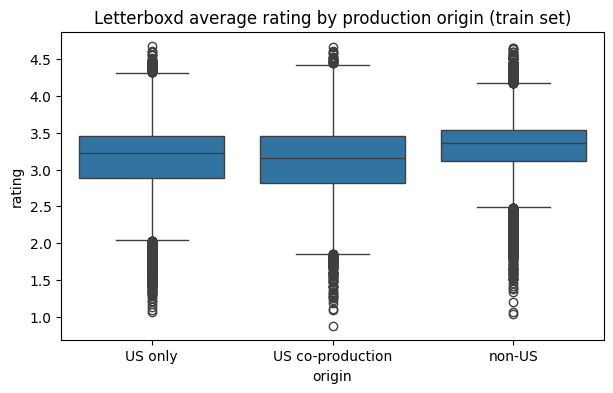

                  count   mean  median    std
origin                                       
US co-production   7562  3.122    3.16  0.491
US only           24685  3.162    3.22  0.455
non-US            37581  3.321    3.36  0.358


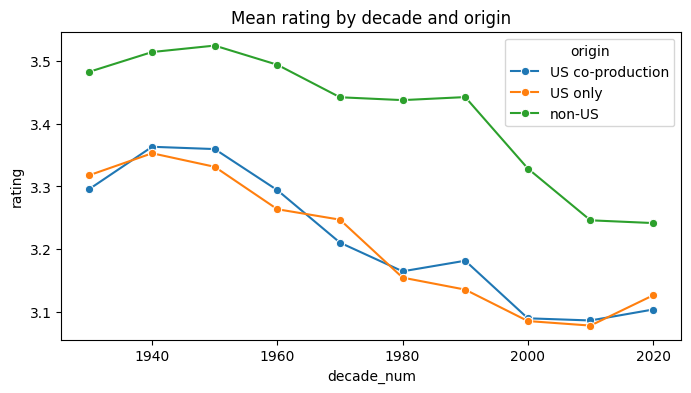

,genre,n,US_only_mean,nonUS_mean,gap
14,Science Fiction,4316,2.899,3.211,-0.311
8,Fantasy,4250,3.015,3.294,-0.279
10,Horror,8689,2.820,3.083,-0.262
0,Action,8284,2.933,3.183,-0.250
16,Thriller,9786,2.940,3.189,-0.248
15,TV Movie,2846,3.067,3.303,-0.236
12,Mystery,4193,3.070,3.298,-0.228
1,Adventure,4787,3.026,3.226,-0.200
7,Family,4542,3.048,3.236,-0.188
6,Drama,30480,3.222,3.386,-0.164


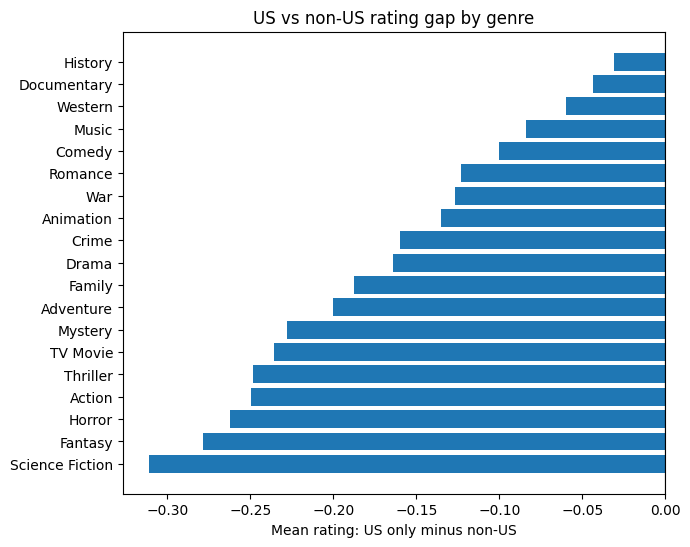

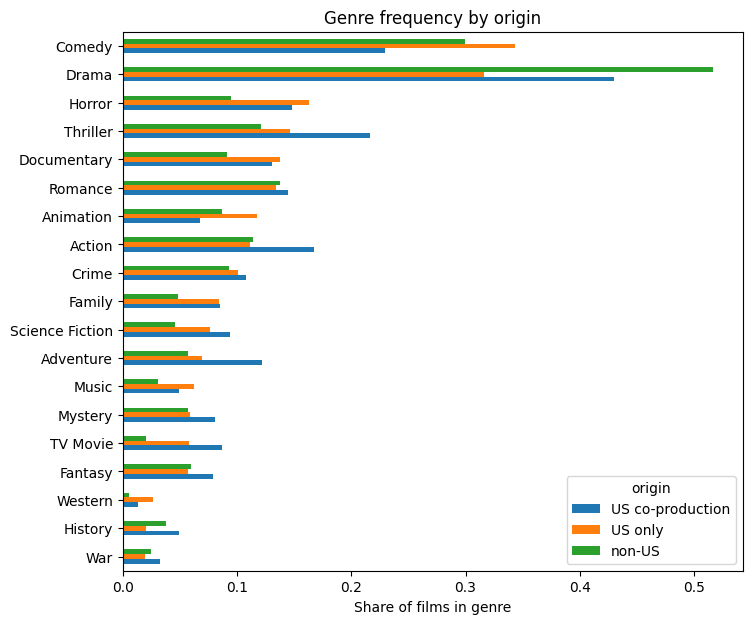

origin,US co-production,US only,non-US,US_minus_nonUS
Heartbreaking and moving family drama,0.038,0.025,0.013,0.012
Intense violence and sexual transgression,0.059,0.031,0.016,0.015
Epic heroes,0.059,0.029,0.012,0.016
Powerful stories of heartbreak and suffering,0.050,0.032,0.015,0.017
Gothic and eerie haunting horror,0.047,0.033,0.014,0.018
Thrillers and murder mysteries,0.037,0.031,0.011,0.020
Suspenseful crime thrillers,0.044,0.034,0.012,0.023
"Creepy, chilling, and terrifying horror",0.047,0.034,0.012,0.023
Touching and sentimental family stories,0.052,0.041,0.016,0.025
Moving relationship stories,0.090,0.054,0.029,0.026


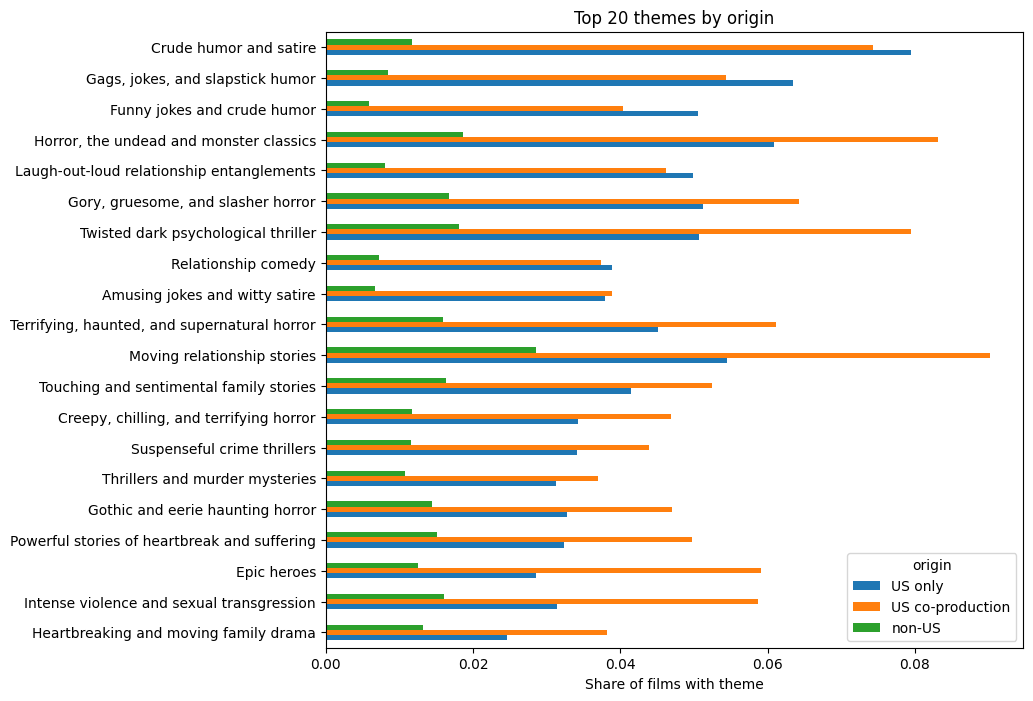

origin
US co-production    0.520
US only             0.387
non-US              0.139
Name: has_any_theme, dtype: float64


origin,US co-production,US only,non-US
Amusing jokes and witty satire,0.075,0.098,0.048
"Creepy, chilling, and terrifying horror",0.090,0.089,0.084
Crude humor and satire,0.143,0.205,0.084
Epic heroes,0.114,0.074,0.090
Funny jokes and crude humor,0.078,0.131,0.042
"Gags, jokes, and slapstick humor",0.104,0.164,0.061
"Gory, gruesome, and slasher horror",0.124,0.132,0.121
Gothic and eerie haunting horror,0.090,0.085,0.104
Heartbreaking and moving family drama,0.073,0.064,0.094
"Horror, the undead and monster classics",0.160,0.157,0.134


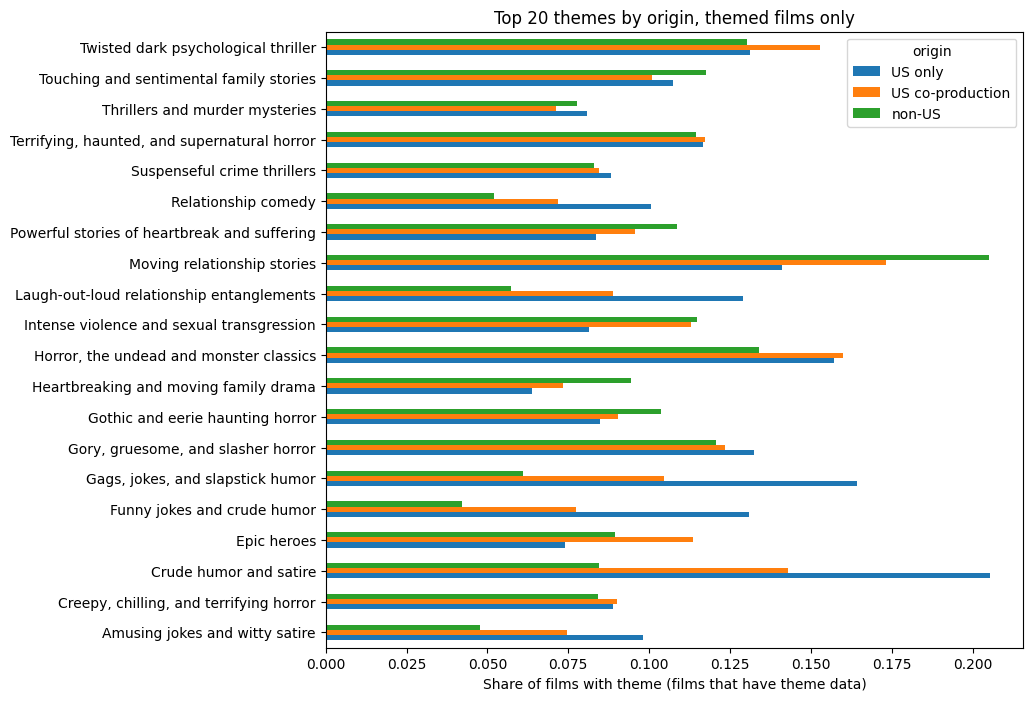

origin
US co-production    0.976
US only             0.952
non-US              0.953
Name: has_cast, dtype: float64


In [7]:
## 4. Exploratory analysis (training set only)

train[["rating", "minute", "year"]].describe()


order = ["US only", "US co-production", "non-US"]
plt.figure(figsize=(7,4))
sns.boxplot(data=train, x="origin", y="rating", order=order)
plt.title("Letterboxd average rating by production origin (train set)")
plt.show()
print(train.groupby("origin")["rating"].agg(["count", "mean", "median", "std"]).round(3))

train["decade_num"] = train["decade"].astype(int)
d = (train[train["decade_num"] >= 1930]
     .groupby(["decade_num", "origin"])["rating"].mean().reset_index())
plt.figure(figsize=(8,4))
sns.lineplot(data=d, x="decade_num", y="rating", hue="origin", marker="o")
plt.title("Mean rating by decade and origin")
plt.show()


# Does the US vs non-US gap vary by genre? (raw gaps)
rows = []
for col in g_cols:
    sub = train[train[col] == 1]
    us  = sub.loc[sub["origin"] == "US only", "rating"]
    non = sub.loc[sub["origin"] == "non-US", "rating"]
    rows.append({"genre": col[2:], "n": len(sub),
                 "US_only_mean": us.mean(), "nonUS_mean": non.mean(),
                 "gap": us.mean() - non.mean()})
gap = pd.DataFrame(rows).sort_values("gap")
display(gap.round(3))

plt.figure(figsize=(7,6))
plt.barh(gap["genre"], gap["gap"])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Mean rating: US only minus non-US")
plt.title("US vs non-US rating gap by genre")
plt.show()


share = train.groupby("origin")[g_cols].mean().T
share.index = [i[2:] for i in share.index]
share.sort_values("US only").plot(kind="barh", figsize=(8,7))
plt.xlabel("Share of films in genre")
plt.title("Genre frequency by origin")
plt.show()


# Theme prevalence by origin (misleading on its own: most films have no theme data)
tshare = train.groupby("origin")[t_cols].mean().T
tshare.index = [i[2:][:45] for i in tshare.index]
tshare["US_minus_nonUS"] = tshare["US only"] - tshare["non-US"]
tshare = tshare.sort_values("US_minus_nonUS")
display(tshare.round(3))
tshare[["US only", "US co-production", "non-US"]].plot(kind="barh", figsize=(9,8))
plt.xlabel("Share of films with theme")
plt.title("Top 20 themes by origin")
plt.show()


# Fair version: only films that have theme data
train["has_any_theme"] = train["id"].isin(set(themes["id"]))
print(train.groupby("origin")["has_any_theme"].mean().round(3))

themed = train[train["has_any_theme"]]
fair = themed.groupby("origin")[t_cols].mean().T
fair.index = [i[2:][:45] for i in fair.index]
display(fair.round(3))
fair[["US only", "US co-production", "non-US"]].plot(kind="barh", figsize=(9, 8))
plt.xlabel("Share of films with theme (films that have theme data)")
plt.title("Top 20 themes by origin, themed films only")
plt.show()


# Cast data coverage by origin (same missingness check as for themes)
train["has_cast"] = train["id"].isin(set(actors["id"]))
print(train.groupby("origin")["has_cast"].mean().round(3))

In [9]:
## 5. Models: one pipeline, same splits and metric for every model
def clip_log(X):
    return np.log1p(np.clip(X, 1, 400))

def make_prep(bin_cols):
    return ColumnTransformer([
        ("runtime", Pipeline([("imp", SimpleImputer(strategy="median")),
                              ("log", FunctionTransformer(clip_log)),
                              ("sc", StandardScaler())]), ["minute"]),
        ("year", StandardScaler(), ["year"]),
        ("origin", OneHotEncoder(categories=[["non-US", "US only", "US co-production"]],
                                 drop="first"), ["origin"]),
        ("bin", "passthrough", bin_cols),
    ])

def make_models():
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Ridge": Ridge(alpha=1.0),
        "Decision tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=42),
        "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=20,
                                               n_jobs=-1, random_state=42),
        "Hist gradient boosting": HistGradientBoostingRegressor(random_state=42),
    }

cv = KFold(5, shuffle=True, random_state=42)
y_train = train["rating"]
rows = []
for fs_name, bin_cols in [("genre only", g_cols), ("genre + themes", g_cols + t_cols)]:
    feats = ["origin", "year", "minute"] + bin_cols
    for name, m in make_models().items():
        pipe = Pipeline([("prep", make_prep(bin_cols)), ("model", m)])
        s = cross_validate(pipe, train[feats], y_train, cv=cv,
                           scoring=["neg_root_mean_squared_error", "r2"])
        rows.append({"features": fs_name, "model": name,
                     "CV RMSE": -s["test_neg_root_mean_squared_error"].mean(),
                     "CV R2": s["test_r2"].mean()})
results = pd.DataFrame(rows).sort_values("CV RMSE").round(3)
display(results)

,features,model,CV RMSE,CV R2
9,genre + themes,Hist gradient boosting,0.311,0.451
8,genre + themes,Random forest,0.315,0.437
4,genre only,Hist gradient boosting,0.315,0.433
3,genre only,Random forest,0.318,0.423
7,genre + themes,Decision tree,0.337,0.352
2,genre only,Decision tree,0.338,0.351
6,genre + themes,Ridge,0.346,0.319
1,genre only,Ridge,0.350,0.301
5,genre + themes,Baseline (mean),0.419,-0.000
0,genre only,Baseline (mean),0.419,-0.000


In [10]:
# Training error is not enough: an unpruned tree memorizes the training set
feats = ["origin", "year", "minute"] + g_cols
tree = Pipeline([("prep", make_prep(g_cols)),
                 ("model", DecisionTreeRegressor(random_state=42))]).fit(train[feats], y_train)
train_rmse = np.sqrt(np.mean((tree.predict(train[feats]) - y_train) ** 2))
cv_rmse = -cross_validate(tree, train[feats], y_train, cv=cv,
                          scoring="neg_root_mean_squared_error")["test_score"].mean()
print(f"Unpruned tree: train RMSE {train_rmse:.3f} vs CV RMSE {cv_rmse:.3f}")

Unpruned tree: train RMSE 0.110 vs CV RMSE 0.439


In [15]:
# Lasso: linear model that shrinks some coefficients to exactly zero
lasso = Pipeline([("prep", make_prep(g_cols)),
                  ("model", LassoCV(cv=5, random_state=42, n_alphas=30))])
s = cross_validate(lasso, train[feats], y_train, cv=cv,
                   scoring=["neg_root_mean_squared_error", "r2"])
print(f"Lasso  CV RMSE {-s['test_neg_root_mean_squared_error'].mean():.3f}   R2 {s['test_r2'].mean():.3f}")

lasso.fit(train[feats], y_train)
names = ["minute", "year", "origin_US only", "origin_US co-production"] + g_cols
coef = pd.Series(lasso.named_steps["model"].coef_, index=names)
print("Dropped to zero:", coef[coef == 0].index.tolist())
display(coef[coef != 0].sort_values().round(3))

Lasso  CV RMSE 0.350   R2 0.301
Dropped to zero: []


,0
g_Horror,-0.231
origin_US only,-0.162
origin_US co-production,-0.149
g_Family,-0.145
g_Action,-0.128
g_Thriller,-0.096
year,-0.091
g_Romance,-0.086
g_Science Fiction,-0.067
g_Adventure,-0.059


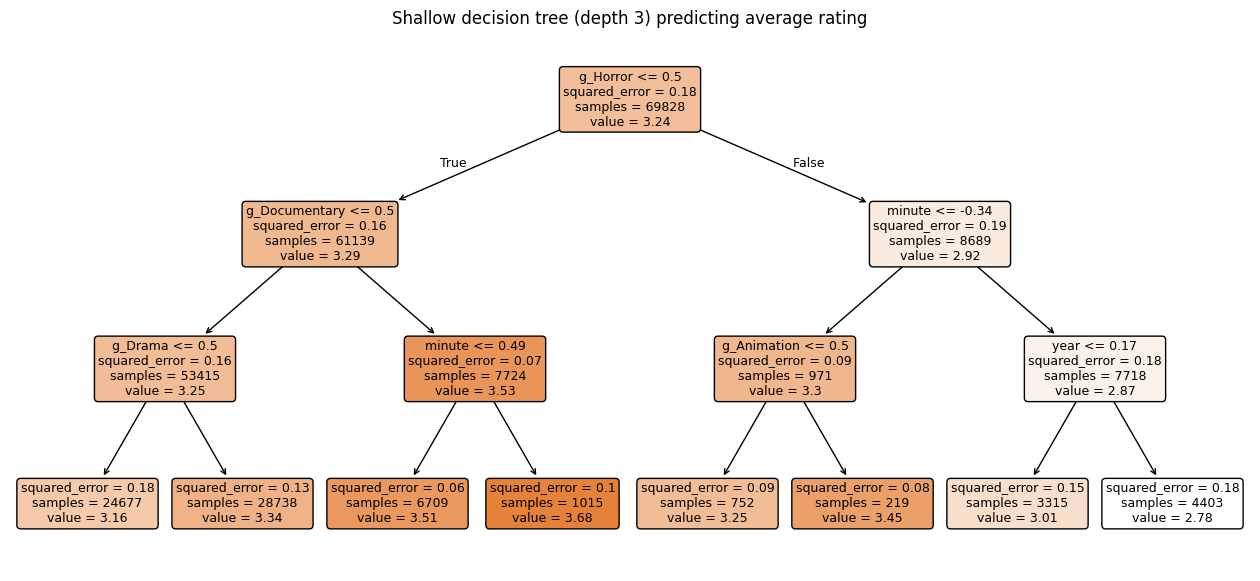

In [16]:
# A shallow tree
prep_vis = make_prep(g_cols).fit(train[feats])
small = DecisionTreeRegressor(max_depth=3, min_samples_leaf=200, random_state=42)
small.fit(prep_vis.transform(train[feats]), y_train)
names = ["minute", "year", "origin_US only", "origin_US co-production"] + g_cols
plt.figure(figsize=(16, 7))
plot_tree(small, feature_names=names, filled=True, rounded=True, fontsize=9, precision=2)
plt.title("Shallow decision tree (depth 3) predicting average rating")
plt.show()

In [14]:
## 6. Fine-tune the best model (training data only)
# Set `FINAL_BIN` to `g_cols + t_cols` only if themes clearly helped.

# %%
FINAL_BIN = g_cols
FINAL_FEATS = ["origin", "year", "minute"] + FINAL_BIN

pipe = Pipeline([("prep", make_prep(FINAL_BIN)),
                 ("model", HistGradientBoostingRegressor(random_state=42))])
params = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [20, 50, 100],
    "model__max_iter": [200, 400],
}
search = RandomizedSearchCV(pipe, params, n_iter=8, cv=3,
                            scoring="neg_root_mean_squared_error",
                            random_state=42, n_jobs=1, verbose=1)
search.fit(train[FINAL_FEATS], y_train)
print("Best params:", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best params: {'model__min_samples_leaf': 20, 'model__max_iter': 200, 'model__max_depth': None, 'model__learning_rate': 0.1}
Best CV RMSE: 0.315


Baseline test RMSE:    0.421
Final model test RMSE: 0.315   R2: 0.441


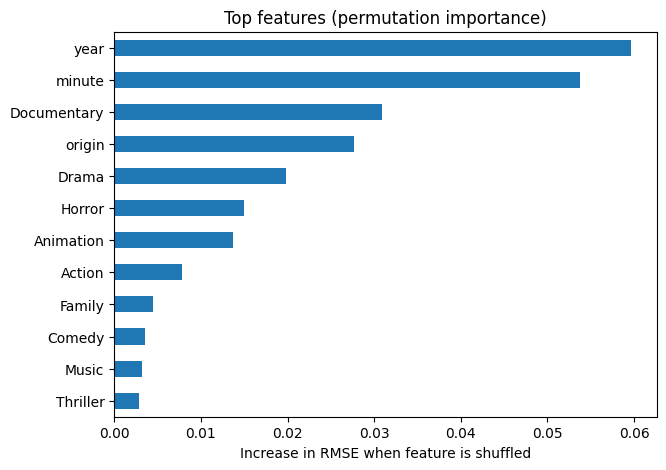

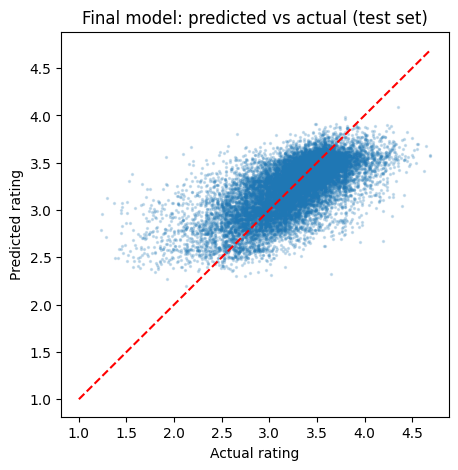

In [17]:
## 7. Evaluate ONCE on the test set

best = search.best_estimator_
y_test = test["rating"]
pred = best.predict(test[FINAL_FEATS])
rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))

print(f"Baseline test RMSE:    {rmse(y_test, np.full(len(y_test), y_train.mean())):.3f}")
print(f"Final model test RMSE: {rmse(y_test, pred):.3f}   R2: {r2_score(y_test, pred):.3f}")

pi = permutation_importance(best, test[FINAL_FEATS], y_test, n_repeats=5,
                            random_state=42, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=FINAL_FEATS).sort_values()
imp.index = [i[2:] if i.startswith(("g_", "t_")) else i for i in imp.index]
imp.tail(12).plot(kind="barh", figsize=(7, 5))
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.title("Top features (permutation importance)")
plt.show()


plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=2, alpha=0.2)
plt.plot([1, 4.7], [1, 4.7], "r--")
plt.xlabel("Actual rating"); plt.ylabel("Predicted rating")
plt.title("Final model: predicted vs actual (test set)")
plt.show()


In [18]:
## 8. Explanation: the US effect with confidence intervals (training set only)

d = train.dropna(subset=["minute"]).copy()
d["log_minute"] = np.log1p(np.clip(d["minute"], 1, 400))
d["us_involved"] = (d["origin"] != "non-US").astype(int)   # US only + co-production vs non-US
gen = " + ".join(f"Q('{c}')" for c in g_cols)

# Does the gap persist after controlling for genre, year, runtime?
m1 = smf.ols(f"rating ~ us_involved + year + log_minute + {gen}", data=d).fit()
print("US-involved effect:", round(m1.params["us_involved"], 3),
      "95% CI:", m1.conf_int().loc["us_involved"].round(3).tolist())

# Does the gap vary by genre? (interaction test)
m2 = smf.ols(f"rating ~ us_involved * ({gen}) + year + log_minute", data=d).fit()
display(anova_lm(m1, m2))

inter = m2.params[m2.params.index.str.contains(":")]
inter.index = [re.search(r"g_([^']+)", i).group(1) for i in inter.index]
display(inter.sort_values().round(3))

# Robustness: does the co-production rule matter?
m3 = smf.ols(f"rating ~ C(origin, Treatment('non-US')) + year + log_minute + {gen}", data=d).fit()
print(m3.params.filter(like="origin").round(3))
print(m3.conf_int().filter(like="origin", axis=0).round(3))

d2 = d[d["origin"].isin(["US only", "non-US"])]
m4 = smf.ols(f"rating ~ us_involved + year + log_minute + {gen}", data=d2).fit()
print("US only vs non-US:", round(m4.params["us_involved"], 3),
      m4.conf_int().loc["us_involved"].round(3).tolist())

US-involved effect: -0.16 95% CI: [-0.165, -0.154]


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,69448.0,8517.715156,0.0,NaN,NaN,NaN
1,69429.0,8427.392533,19.0,90.322622,39.164323,1.048260e-144


,0
Family,-0.104
Horror,-0.075
Action,-0.061
Fantasy,-0.049
Thriller,-0.046
Romance,-0.028
Crime,-0.026
Science Fiction,-0.024
Drama,-0.012
TV Movie,-0.010


C(origin, Treatment('non-US'))[T.US co-production]   -0.151
C(origin, Treatment('non-US'))[T.US only]            -0.163
dtype: float64
                                                        0      1
C(origin, Treatment('non-US'))[T.US co-production] -0.160 -0.142
C(origin, Treatment('non-US'))[T.US only]          -0.169 -0.157
US only vs non-US: -0.164 [-0.17, -0.158]


**9. Low / Medium / High rating tiers (classification)**

Low < 3.13 <= Medium < 3.44 <= High
tier
High      0.336
Medium    0.333
Low       0.331
Name: proportion, dtype: float64


tier,Low,Medium,High
origin,,,
US only,0.411,0.317,0.272
US co-production,0.472,0.259,0.269
non-US,0.250,0.358,0.391


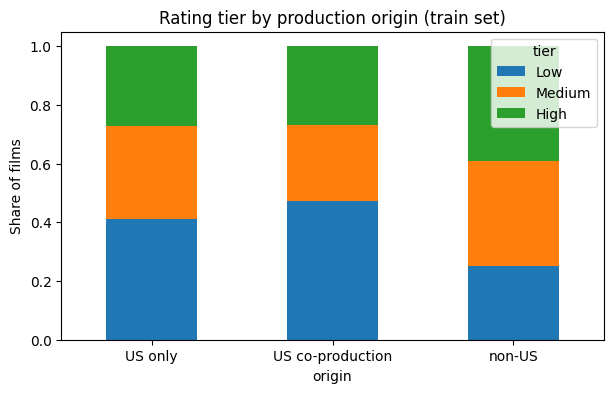

In [20]:
q1, q2 = train["rating"].quantile([1/3, 2/3])
labels = ["Low", "Medium", "High"]
origin_order = ["US only", "US co-production", "non-US"]

def to_tier(r):
    return pd.cut(r, [-np.inf, q1, q2, np.inf], labels=labels, right=False).astype(str)

train["tier"] = to_tier(train["rating"])
test["tier"]  = to_tier(test["rating"])

print(f"Low < {q1:.2f} <= Medium < {q2:.2f} <= High")
print(train["tier"].value_counts(normalize=True).round(3))

by_origin = pd.crosstab(train["origin"], train["tier"], normalize="index")[labels].loc[origin_order]
display(by_origin.round(3))
by_origin.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.ylabel("Share of films"); plt.title("Rating tier by production origin (train set)")
plt.xticks(rotation=0); plt.show()

In [21]:
feats_clf = ["origin", "year", "minute"] + g_cols
y_tier = train["tier"]
skf = StratifiedKFold(5, shuffle=True, random_state=42)

clf_models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20,
                                            n_jobs=-1, random_state=42),
    "Hist gradient boosting": HistGradientBoostingClassifier(random_state=42),
}

rows = []
for name, m in clf_models.items():
    pipe = Pipeline([("prep", make_prep(g_cols)), ("model", m)])
    s = cross_validate(pipe, train[feats_clf], y_tier, cv=skf, scoring=["accuracy", "f1_macro"])
    rows.append({"model": name, "CV accuracy": s["test_accuracy"].mean(),
                 "CV macro-F1": s["test_f1_macro"].mean()})
clf_results = pd.DataFrame(rows).sort_values("CV macro-F1", ascending=False).round(3)
display(clf_results)

,model,CV accuracy,CV macro-F1
4,Hist gradient boosting,0.609,0.606
3,Random forest,0.602,0.598
2,Decision tree,0.576,0.573
1,Logistic regression,0.550,0.540
0,Baseline (most frequent),0.336,0.168


Chosen model: Hist gradient boosting
Baseline test accuracy: 0.336   macro-F1: 0.168
Model test accuracy:    0.612   macro-F1: 0.609


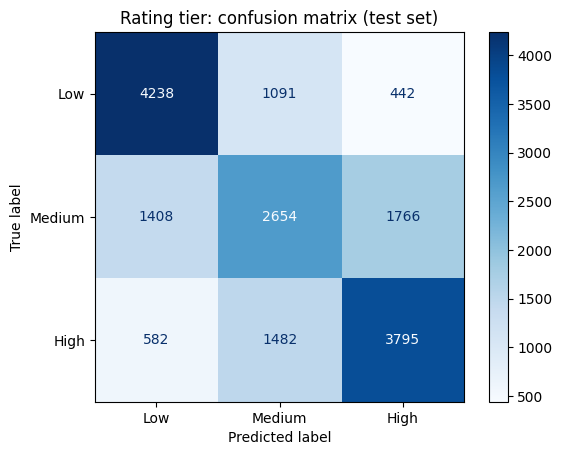

Share of films misclassified two tiers (Low<->High): 0.059
Accuracy by origin:
origin
US co-production    0.650
US only             0.644
non-US              0.584
dtype: float64


In [22]:
# Evaluate ONCE on the test set (model chosen by CV macro-F1)
best_name = clf_results.iloc[0]["model"]
best_clf = Pipeline([("prep", make_prep(g_cols)),
                     ("model", clf_models[best_name])]).fit(train[feats_clf], y_tier)
y_t = test["tier"]
pred_t = best_clf.predict(test[feats_clf])

base = DummyClassifier(strategy="most_frequent").fit(train[feats_clf], y_tier)
base_pred = base.predict(test[feats_clf])
print("Chosen model:", best_name)
print(f"Baseline test accuracy: {accuracy_score(y_t, base_pred):.3f}   macro-F1: {f1_score(y_t, base_pred, average='macro'):.3f}")
print(f"Model test accuracy:    {accuracy_score(y_t, pred_t):.3f}   macro-F1: {f1_score(y_t, pred_t, average='macro'):.3f}")

cm = confusion_matrix(y_t, pred_t, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Rating tier: confusion matrix (test set)"); plt.show()
print(f"Share of films misclassified two tiers (Low<->High): {(cm[0, 2] + cm[2, 0]) / cm.sum():.3f}")

correct = pd.Series(pred_t == y_t.values, index=test.index)
print("Accuracy by origin:")
print(correct.groupby(test["origin"]).mean().round(3))

**10. Does casting change the US effect?**


In [23]:
print(actors.shape, actors.columns.tolist())
display(actors.head())

actor_col = "name" if "name" in actors.columns else [c for c in actors.columns if c != "id"][0]
print("Using actor column:", actor_col)

a = actors.dropna(subset=[actor_col]).drop_duplicates(["id", actor_col])
cast_size = a.groupby("id").size().rename("cast_size")

# Top 200 actors chosen from TRAINING films only
a_train = a[a["id"].isin(train["id"])]
top_actors = set(a_train[actor_col].value_counts().head(200).index)
top_count = a[a[actor_col].isin(top_actors)].groupby("id").size().rename("top_actors")

cf = pd.concat([cast_size, top_count], axis=1).fillna({"top_actors": 0})

def add_cast(frame):
    f = frame.merge(cf, left_on="id", right_index=True, how="left")
    f["has_cast"] = f["cast_size"].notna()
    f["log_cast"] = np.log1p(f["cast_size"])
    return f

train_c, test_c = add_cast(train), add_cast(test)
print(train_c.groupby("origin")["has_cast"].mean().round(3))
print(train_c[train_c["has_cast"]].groupby("origin")[["cast_size", "top_actors"]].mean().round(2))

(5798450, 3) ['id', 'name', 'role']


,id,name,role
0,1000001,Margot Robbie,Barbie
1,1000001,Ryan Gosling,Ken
2,1000001,America Ferrera,Gloria
3,1000001,Ariana Greenblatt,Sasha
4,1000001,Issa Rae,Barbie


Using actor column: name
origin
US co-production    0.976
US only             0.952
non-US              0.953
Name: has_cast, dtype: float64
                  cast_size  top_actors
origin                                 
US co-production      23.15        0.29
US only               21.15        0.48
non-US                16.52        0.15


In [24]:
dc = train_c[train_c["has_cast"] & train_c["minute"].notna()].copy()
dc["log_minute"] = np.log1p(np.clip(dc["minute"], 1, 400))
dc["us_involved"] = (dc["origin"] != "non-US").astype(int)
gen = " + ".join(f"Q('{c}')" for c in g_cols)

m_a = smf.ols(f"rating ~ us_involved + year + log_minute + {gen}", data=dc).fit()
m_b = smf.ols(f"rating ~ us_involved + year + log_minute + log_cast + top_actors + {gen}", data=dc).fit()

def summarize(m, name):
    ci = m.conf_int().loc["us_involved"]
    return {"model": name, "n": int(m.nobs), "US coef": m.params["us_involved"],
            "CI low": ci[0], "CI high": ci[1], "R2": m.rsquared, "resid SD": np.sqrt(m.scale)}

display(pd.DataFrame([summarize(m_a, "without cast"), summarize(m_b, "with cast")]).round(3))
print(m_b.params[["log_cast", "top_actors"]].round(3))
print("Change in US coefficient:", round(m_b.params["us_involved"] - m_a.params["us_involved"], 3))

,model,n,US coef,CI low,CI high,R2,resid SD
0,without cast,66385,-0.170,-0.175,-0.164,0.307,0.352
1,with cast,66385,-0.166,-0.172,-0.160,0.308,0.352


log_cast     -0.022
top_actors    0.009
dtype: float64
Change in US coefficient: 0.003


In [25]:
dcv = train_c[train_c["has_cast"]]
base_feats = ["origin", "year", "minute"] + g_cols
cast_feats = base_feats + ["log_cast", "top_actors"]

res = {}
for name, feats, binc in [("without cast", base_feats, g_cols),
                          ("with cast", cast_feats, g_cols + ["log_cast", "top_actors"])]:
    pipe = Pipeline([("prep", make_prep(binc)), ("model", HistGradientBoostingRegressor(random_state=42))])
    s = cross_validate(pipe, dcv[feats], dcv["rating"], cv=cv,
                       scoring=["neg_root_mean_squared_error", "r2"])
    res[name] = (-s["test_neg_root_mean_squared_error"].mean(), s["test_r2"].mean())
display(pd.DataFrame(res, index=["CV RMSE", "CV R2"]).T.round(3))

# One test evaluation on test films that have cast data
tc = test_c[test_c["has_cast"]]
for name, feats, binc in [("without cast", base_feats, g_cols),
                          ("with cast", cast_feats, g_cols + ["log_cast", "top_actors"])]:
    pipe = Pipeline([("prep", make_prep(binc)), ("model", HistGradientBoostingRegressor(random_state=42))])
    pipe.fit(dcv[feats], dcv["rating"])
    p = pipe.predict(tc[feats])
    print(f"{name:13s} test RMSE {np.sqrt(mean_squared_error(tc['rating'], p)):.3f}   R2 {r2_score(tc['rating'], p):.3f}")

,CV RMSE,CV R2
without cast,0.319,0.430
with cast,0.316,0.441


without cast  test RMSE 0.319   R2 0.435
with cast     test RMSE 0.315   R2 0.448
